# MScFE 620 Derivative Pricing - Group Work Project #1

**Course:** MScFE 620 Derivative Pricing  
**Project Type:** Group Work Project #1  

## Key Parameters
- **S₀ = 100** (Initial stock price)
- **r = 5%** (Risk-free rate)
- **σ = 20%** (Volatility)
- **T = 3 months** (Time to expiration)

## Team Structure:
- **Part A (Gastive):** European Options (Binomial Tree) - Questions 5-7, American Options (Trinomial Tree) - Questions 17-18
- **Part B (Vincent):** American Options (Binomial Tree) - Questions 8-10, European Options (Trinomial Tree) - Questions 15-16
- **Part C (Hitesh):** Verification and Analysis - Questions 11-14, 19-24, Dynamic Hedging - Questions 25-27

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import exp, sqrt, log
from scipy.stats import norm
import os

# Create directories
os.makedirs('CSV', exist_ok=True)
os.makedirs('figures', exist_ok=True)

# Parameters
S0 = 100
r = 0.05
sigma = 0.20
T = 0.25  # 3 months
K_ATM = 100
strikes = [90, 95, 100, 105, 110]

---
# PART A - Gastive
## European Options (Binomial Tree) - Questions 5-7
## American Options (Trinomial Tree) - Questions 17-18
---

### Question 5: European Call and Put (Binomial Tree)

In [2]:
def binomial_tree_european(S0, K, T, r, sigma, n, option_type='call'):
    dt = T / n
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    df = np.exp(-r * dt)
    p = (np.exp(r * dt) - d) / (u - d)

    # Initialize stock prices at maturity
    stock_prices = np.zeros(n + 1)
    for j in range(n + 1):
        stock_prices[j] = S0 * (u ** j) * (d ** (n - j))

    # Calculate option values at maturity
    option_values = np.zeros(n + 1)
    for j in range(n + 1):
        if option_type == 'call':
            option_values[j] = max(stock_prices[j] - K, 0)
        else:  # put
            option_values[j] = max(K - stock_prices[j], 0)

    # Backward induction
    for i in range(n - 1, -1, -1):
        for j in range(i + 1):
            option_values[j] = df * (p * option_values[j + 1] + (1 - p) * option_values[j])

    return option_values[0]

# Price European options with n=100 steps
call_price = binomial_tree_european(S0, K_ATM, T, r, sigma, 100, 'call')
put_price = binomial_tree_european(S0, K_ATM, T, r, sigma, 100, 'put')

print(f"European Call Price (n=100): ${call_price:.4f}")
print(f"European Put Price (n=100): ${put_price:.4f}")

# Verify put-call parity
discounted_strike = K_ATM * np.exp(-r * T)
parity_check = call_price - put_price - (S0 - discounted_strike)
print(f"\nPut-Call Parity Check: {parity_check:.6f} (should be ~0)")

European Call Price (n=100): $4.6050
European Put Price (n=100): $3.3628

Put-Call Parity Check: -0.000000 (should be ~0)


### Question 6: Delta Calculation

In [3]:
def binomial_tree_delta(S0, K, T, r, sigma, n):
    dt = T / n
    u = np.exp(sigma * np.sqrt(dt))
    d = 1 / u
    
    # Calculate option values at first up/down nodes
    call_up = binomial_tree_european(S0*u, K, T-dt, r, sigma, n-1, 'call')
    call_down = binomial_tree_european(S0*d, K, T-dt, r, sigma, n-1, 'call')
    put_up = binomial_tree_european(S0*u, K, T-dt, r, sigma, n-1, 'put')
    put_down = binomial_tree_european(S0*d, K, T-dt, r, sigma, n-1, 'put')
    
    # Compute deltas
    delta_call = (call_up - call_down) / (S0*u - S0*d)
    delta_put = (put_up - put_down) / (S0*u - S0*d)
    
    return delta_call, delta_put

# Calculate deltas
delta_call, delta_put = binomial_tree_delta(S0, K_ATM, T, r, sigma, 100)

print(f"European Call Delta: {delta_call:.4f}")
print(f"European Put Delta: {delta_put:.4f}")
print(f"Delta relationship (Call - Put): {delta_call - delta_put:.4f} (should be ~1.0)")

European Call Delta: 0.5693
European Put Delta: -0.4307
Delta relationship (Call - Put): 1.0000 (should be ~1.0)


### Question 7: Volatility Sensitivity

In [4]:
# Calculate prices with increased volatility (25%)
sigma_high = 0.25
call_price_high_vol = binomial_tree_european(S0, K_ATM, T, r, sigma_high, 100, 'call')
put_price_high_vol = binomial_tree_european(S0, K_ATM, T, r, sigma_high, 100, 'put')

# Calculate sensitivity
call_vega_change = call_price_high_vol - call_price
put_vega_change = put_price_high_vol - put_price

print(f"Volatility Sensitivity (20% → 25%):")
print(f"Call: ${call_price:.4f} → ${call_price_high_vol:.4f} (Change: +${call_vega_change:.4f})")
print(f"Put: ${put_price:.4f} → ${put_price_high_vol:.4f} (Change: +${put_vega_change:.4f})")

# Save results
step1_data = pd.DataFrame({
    'Instrument': ['European Call (ATM)', 'European Put (ATM)'],
    'Price': [call_price, put_price],
    'Delta': [delta_call, delta_put]
})
step1_data.to_csv('CSV/A_step1_prices_deltas.csv', index=False)

vega_data = pd.DataFrame({
    'Instrument': ['European Call', 'European Put'],
    'Price @20%': [call_price, put_price],
    'Price @25%': [call_price_high_vol, put_price_high_vol],
    'Change': [call_vega_change, put_vega_change]
})
vega_data.to_csv('CSV/A_step1_vega.csv', index=False)

Volatility Sensitivity (20% → 25%):
Call: $4.6050 → $5.5860 (Change: +$0.9809)
Put: $3.3628 → $4.3438 (Change: +$0.9809)


### Questions 17-18: American Options (Trinomial Tree)

In [5]:
def trinomial_tree_american(S0, K, T, r, sigma, n, option_type='call'):
    dt = T / n
    dx = sigma * np.sqrt(3 * dt)
    nu = r - 0.5 * sigma**2
    pu = 0.5 * ((sigma**2 * dt + nu**2 * dt**2) / dx**2 + (nu * dt) / dx)
    pd = 0.5 * ((sigma**2 * dt + nu**2 * dt**2) / dx**2 - (nu * dt) / dx)
    pm = 1.0 - pu - pd
    discount = np.exp(-r * dt)

    # Initialize asset prices and option values at maturity
    j_max = n
    j_min = -n
    option_values = np.zeros(2 * n + 1)

    for j in range(j_min, j_max + 1):
        S_T = S0 * np.exp(j * dx)
        if option_type == 'call':
            option_values[j - j_min] = max(S_T - K, 0)
        else:  # put
            option_values[j - j_min] = max(K - S_T, 0)

    # Backward induction through the tree
    for i in range(n - 1, -1, -1):
        new_option_values = np.zeros(2 * i + 1)
        for j in range(-i, i + 1):
            index = j - j_min
            continuation = discount * (
                pu * option_values[index + 1] +
                pm * option_values[index] +
                pd * option_values[index - 1]
            )
            S_ij = S0 * np.exp(j * dx)

            if option_type == 'call':
                exercise_value = max(S_ij - K, 0)
            else:  # put
                exercise_value = max(K - S_ij, 0)

            new_option_values[j + i] = max(continuation, exercise_value)
        option_values = new_option_values
        j_min += 1

    return option_values[0]

# Price American options for all strikes
american_call_prices = {}
american_put_prices = {}

for K in strikes:
    american_call_prices[K] = trinomial_tree_american(S0, K, T, r, sigma, 100, 'call')
    american_put_prices[K] = trinomial_tree_american(S0, K, T, r, sigma, 100, 'put')

# Display results
print("American Option Prices (Trinomial Tree):")
print(f"{'Strike':<8} {'Call':<10} {'Put':<10}")
for K in strikes:
    print(f"{K:<8} ${american_call_prices[K]:<9.4f} ${american_put_prices[K]:<9.4f}")

# Save results
calls_df = pd.DataFrame({
    'Strike': strikes,
    'American Call': [american_call_prices[K] for K in strikes]
})
calls_df.to_csv('CSV/A_trinomial_american_calls.csv', index=False)

puts_df = pd.DataFrame({
    'Strike': strikes,
    'American Put': [american_put_prices[K] for K in strikes]
})
puts_df.to_csv('CSV/A_trinomial_american_puts.csv', index=False)

American Option Prices (Trinomial Tree):
Strike   Call       Put       
90       $11.6674   $0.5600   
95       $7.7083    $1.5666   
100      $4.6052    $3.4705   
105      $2.4770    $6.4199   
110      $1.1948    $10.3282  


---
# PART B - VINCENT
## American Options (Binomial Tree) - Questions 8-10
## European Options (Trinomial Tree) - Questions 15-16
---

### Question 8: American ATM Options (Binomial Tree)

In [6]:
def binomial_tree_american(S0, K, r, sigma, T, n, option_type):
    dt = T / n
    u = exp(sigma * sqrt(dt))
    d = 1 / u
    p = (exp(r * dt) - d) / (u - d)
    
    # Initialize asset prices at maturity
    S = np.zeros((n + 1, n + 1))
    for i in range(n + 1):
        for j in range(i + 1):
            S[j, i] = S0 * (u ** (i - j)) * (d ** j)
    
    # Initialize option values at maturity
    V = np.zeros((n + 1, n + 1))
    for j in range(n + 1):
        if option_type == 'call':
            V[j, n] = max(0, S[j, n] - K)
        else:  # put
            V[j, n] = max(0, K - S[j, n])
    
    # Backward induction
    for i in range(n - 1, -1, -1):
        for j in range(i + 1):
            # European value
            european_value = exp(-r * dt) * (p * V[j, i + 1] + (1 - p) * V[j + 1, i + 1])
            
            # Early exercise value
            if option_type == 'call':
                exercise_value = max(0, S[j, i] - K)
            else:  # put
                exercise_value = max(0, K - S[j, i])
            
            # American option value
            V[j, i] = max(european_value, exercise_value)
    
    return V[0, 0]

# Calculate American option prices
n = 110
american_call_price = binomial_tree_american(S0, K_ATM, r, sigma, T, n, 'call')
american_put_price = binomial_tree_american(S0, K_ATM, r, sigma, T, n, 'put')

print(f"American Call (ATM): ${american_call_price:.2f}")
print(f"American Put (ATM): ${american_put_price:.2f}")

American Call (ATM): $4.61
American Put (ATM): $3.48


### Question 9: Delta for American Options

In [7]:
def calculate_delta_american(S0, K, r, sigma, T, n, option_type):
    dS = 0.01  # Small change in stock price
    
    price_up = binomial_tree_american(S0 + dS, K, r, sigma, T, n, option_type)
    price_down = binomial_tree_american(S0 - dS, K, r, sigma, T, n, option_type)
    
    delta = (price_up - price_down) / (2 * dS)
    return delta

# Calculate American option deltas
american_call_delta = calculate_delta_american(S0, K_ATM, r, sigma, T, n, 'call')
american_put_delta = calculate_delta_american(S0, K_ATM, r, sigma, T, n, 'put')

print(f"American Call Delta: {american_call_delta:.4f}")
print(f"American Put Delta: {american_put_delta:.4f}")
print(f"Sum of deltas: {american_call_delta + american_put_delta:.4f}")

American Call Delta: 0.5693
American Put Delta: -0.4639
Sum of deltas: 0.1054


### Question 10: Volatility Sensitivity

In [8]:
# Calculate option prices with higher volatility (25%)
sigma_high = 0.25
american_call_price_high_vol = binomial_tree_american(S0, K_ATM, r, sigma_high, T, n, 'call')
american_put_price_high_vol = binomial_tree_american(S0, K_ATM, r, sigma_high, T, n, 'put')

# Calculate absolute price changes
call_vega_change = american_call_price_high_vol - american_call_price
put_vega_change = american_put_price_high_vol - american_put_price

print(f"Volatility Sensitivity Analysis (20% → 25%)")
print(f"American Call: ${american_call_price:.2f} → ${american_call_price_high_vol:.2f} (Change: +${call_vega_change:.2f})")
print(f"American Put: ${american_put_price:.2f} → ${american_put_price_high_vol:.2f} (Change: +${put_vega_change:.2f})")

# Save Step 1 results
step1_data = pd.DataFrame({
    'Instrument': ['American Call (ATM)', 'American Put (ATM)'],
    'Price': [american_call_price, american_put_price],
    'Delta': [american_call_delta, american_put_delta]
})
step1_data.to_csv('CSV/B_step1_prices_deltas.csv', index=False)

vega_data = pd.DataFrame({
    'Instrument': ['American Call', 'American Put'],
    'Price @20%': [american_call_price, american_put_price],
    'Price @25%': [american_call_price_high_vol, american_put_price_high_vol],
    'Change': [call_vega_change, put_vega_change]
})
vega_data.to_csv('CSV/B_step1_vega.csv', index=False)

Volatility Sensitivity Analysis (20% → 25%)
American Call: $4.61 → $5.59 (Change: +$0.98)
American Put: $3.48 → $4.45 (Change: +$0.98)


### Questions 15-16: European Options (Trinomial Tree)

In [9]:
def trinomial_tree_european(S0, K, r, sigma, T, n, option_type):
    dt = T / n
    u = exp(sigma * sqrt(2 * dt))
    d = 1 / u
    m = 1  # middle factor
    
    # Risk-neutral probabilities
    pu = ((exp(r * dt / 2) - exp(-sigma * sqrt(dt / 2))) / 
          (exp(sigma * sqrt(dt / 2)) - exp(-sigma * sqrt(dt / 2)))) ** 2
    pd = ((exp(sigma * sqrt(dt / 2)) - exp(r * dt / 2)) / 
          (exp(sigma * sqrt(dt / 2)) - exp(-sigma * sqrt(dt / 2)))) ** 2
    pm = 1 - pu - pd
    
    # Initialize asset prices at maturity
    S = {}
    for i in range(2 * n + 1):
        S[i] = S0 * (u ** max(i - n, 0)) * (d ** max(n - i, 0))
    
    # Initialize option values at maturity
    V = {}
    for i in range(2 * n + 1):
        if option_type == 'call':
            V[i] = max(0, S[i] - K)
        else:  # put
            V[i] = max(0, K - S[i])
    
    # Backward induction
    for step in range(n - 1, -1, -1):
        V_new = {}
        for i in range(2 * step + 1):
            V_new[i] = exp(-r * dt) * (pu * V[i + 2] + pm * V[i + 1] + pd * V[i])
        V = V_new
    
    return V[0]

# Calculate European option prices for all strikes
european_calls = []
european_puts = []

for K in strikes:
    call_price = trinomial_tree_european(S0, K, r, sigma, T, n, 'call')
    put_price = trinomial_tree_european(S0, K, r, sigma, T, n, 'put')
    european_calls.append(round(call_price, 2))
    european_puts.append(round(put_price, 2))

# Display results
results_df = pd.DataFrame({
    'Strike': strikes,
    'European Call': european_calls,
    'European Put': european_puts
})

print("European Option Prices (Trinomial Tree):")
print(results_df.to_string(index=False))

# Save results
calls_df = pd.DataFrame({
    'Strike': strikes,
    'European Call': european_calls
})
calls_df.to_csv('CSV/B_trinomial_european_calls.csv', index=False)

puts_df = pd.DataFrame({
    'Strike': strikes,
    'European Put': european_puts
})
puts_df.to_csv('CSV/B_trinomial_european_puts.csv', index=False)

European Option Prices (Trinomial Tree):
 Strike  European Call  European Put
     90          11.67          0.55
     95           7.72          1.54
    100           4.61          3.37
    105           2.48          6.18
    110           1.19          9.82


---
# PART C - HITESH
## Verification and Analysis - Questions 11-14, 19-24
## Dynamic Hedging - Questions 25-27
---

### Load Results from Parts A and B

In [10]:
# Load results from Parts A and B
a_calls = pd.read_csv('CSV/A_trinomial_american_calls.csv')
a_puts = pd.read_csv('CSV/A_trinomial_american_puts.csv')
b_calls = pd.read_csv('CSV/B_trinomial_european_calls.csv')
b_puts = pd.read_csv('CSV/B_trinomial_european_puts.csv')

# Combine all option prices
all_options = pd.DataFrame({
    'Strike': strikes,
    'American_Call': a_calls['American Call'].values,
    'American_Put': a_puts['American Put'].values,
    'European_Call': b_calls['European Call'].values,
    'European_Put': b_puts['European Put'].values
})

print("All Option Prices:")
print(all_options.round(4))

All Option Prices:
   Strike  American_Call  American_Put  European_Call  European_Put
0      90        11.6674        0.5600          11.67          0.55
1      95         7.7083        1.5666           7.72          1.54
2     100         4.6052        3.4705           4.61          3.37
3     105         2.4770        6.4199           2.48          6.18
4     110         1.1948       10.3282           1.19          9.82


### Question 11: Black-Scholes Comparison

In [11]:
def black_scholes(S, K, T, r, sigma, option_type='call'):
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    
    if option_type == 'call':
        return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
    else:
        return K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)

# Calculate Black-Scholes prices
bs_calls = [black_scholes(S0, K, T, r, sigma, 'call') for K in strikes]
bs_puts = [black_scholes(S0, K, T, r, sigma, 'put') for K in strikes]

# Compare with European options from trinomial tree
comparison = pd.DataFrame({
    'Strike': strikes,
    'BS_Call': bs_calls,
    'Trinomial_Call': all_options['European_Call'],
    'Call_Diff': np.array(bs_calls) - all_options['European_Call'].values,
    'BS_Put': bs_puts,
    'Trinomial_Put': all_options['European_Put'],
    'Put_Diff': np.array(bs_puts) - all_options['European_Put'].values
})

print("Black-Scholes vs Trinomial Comparison:")
print(comparison.round(4))
print(f"\nMax Call Difference: {abs(comparison['Call_Diff']).max():.6f}")
print(f"Max Put Difference: {abs(comparison['Put_Diff']).max():.6f}")

Black-Scholes vs Trinomial Comparison:
   Strike  BS_Call  Trinomial_Call  Call_Diff  BS_Put  Trinomial_Put  Put_Diff
0      90  11.6701           11.67     0.0001  0.5521           0.55    0.0021
1      95   7.7144            7.72    -0.0056  1.5343           1.54   -0.0057
2     100   4.6150            4.61     0.0050  3.3728           3.37    0.0028
3     105   2.4779            2.48    -0.0021  6.1736           6.18   -0.0064
4     110   1.1911            1.19     0.0011  9.8247           9.82    0.0047

Max Call Difference: 0.005631
Max Put Difference: 0.006429


### Question 12: Put-Call Parity Verification

In [12]:
# European Put-Call Parity: C - P = S0 - K*e^(-rT)
discounted_strikes = [K * np.exp(-r * T) for K in strikes]
theoretical_diff = [S0 - K_disc for K_disc in discounted_strikes]
actual_diff = all_options['European_Call'] - all_options['European_Put']
parity_error = actual_diff - theoretical_diff

european_parity = pd.DataFrame({
    'Strike': strikes,
    'Call': all_options['European_Call'],
    'Put': all_options['European_Put'],
    'C-P': actual_diff,
    'S0-Ke^(-rT)': theoretical_diff,
    'Parity_Error': parity_error
})

print("European Put-Call Parity Verification:")
print(european_parity.round(6))

# American Put-Call Parity: S0 - K <= C - P <= S0 - K*e^(-rT)
american_diff = all_options['American_Call'] - all_options['American_Put']
lower_bound = [S0 - K for K in strikes]
upper_bound = theoretical_diff

american_parity = pd.DataFrame({
    'Strike': strikes,
    'C-P': american_diff,
    'Lower_Bound': lower_bound,
    'Upper_Bound': upper_bound,
    'Within_Bounds': [(lb <= cp <= ub) for cp, lb, ub in zip(american_diff, lower_bound, upper_bound)]
})

print("\nAmerican Put-Call Parity Verification:")
print(american_parity.round(4))

European Put-Call Parity Verification:
   Strike   Call   Put    C-P  S0-Ke^(-rT)  Parity_Error
0      90  11.67  0.55  11.12    11.117998      0.002002
1      95   7.72  1.54   6.18     6.180109     -0.000109
2     100   4.61  3.37   1.24     1.242220     -0.002220
3     105   2.48  6.18  -3.70    -3.695669     -0.004331
4     110   1.19  9.82  -8.63    -8.633558      0.003558

American Put-Call Parity Verification:
   Strike      C-P  Lower_Bound  Upper_Bound  Within_Bounds
0      90  11.1074           10      11.1180           True
1      95   6.1417            5       6.1801           True
2     100   1.1347            0       1.2422           True
3     105  -3.9429           -5      -3.6957           True
4     110  -9.1334          -10      -8.6336           True


### Question 13: American vs European Premium

In [13]:
# Calculate American premium (American - European)
call_premium = all_options['American_Call'] - all_options['European_Call']
put_premium = all_options['American_Put'] - all_options['European_Put']

premium_analysis = pd.DataFrame({
    'Strike': strikes,
    'Moneyness': [K/S0 for K in strikes],
    'American_Call': all_options['American_Call'],
    'European_Call': all_options['European_Call'],
    'Call_Premium': call_premium,
    'American_Put': all_options['American_Put'],
    'European_Put': all_options['European_Put'],
    'Put_Premium': put_premium
})

print("American vs European Premium Analysis:")
print(premium_analysis.round(4))

print(f"\nCall Premium - Max: {call_premium.max():.4f} at Strike {strikes[call_premium.idxmax()]}")
print(f"Put Premium - Max: {put_premium.max():.4f} at Strike {strikes[put_premium.idxmax()]}")

American vs European Premium Analysis:
   Strike  Moneyness  American_Call  European_Call  Call_Premium  \
0      90       0.90        11.6674          11.67       -0.0026   
1      95       0.95         7.7083           7.72       -0.0117   
2     100       1.00         4.6052           4.61       -0.0048   
3     105       1.05         2.4770           2.48       -0.0030   
4     110       1.10         1.1948           1.19        0.0048   

   American_Put  European_Put  Put_Premium  
0        0.5600          0.55       0.0100  
1        1.5666          1.54       0.0266  
2        3.4705          3.37       0.1005  
3        6.4199          6.18       0.2399  
4       10.3282          9.82       0.5082  

Call Premium - Max: 0.0048 at Strike 110
Put Premium - Max: 0.5082 at Strike 110


### Question 14: Comprehensive Analysis Visualization

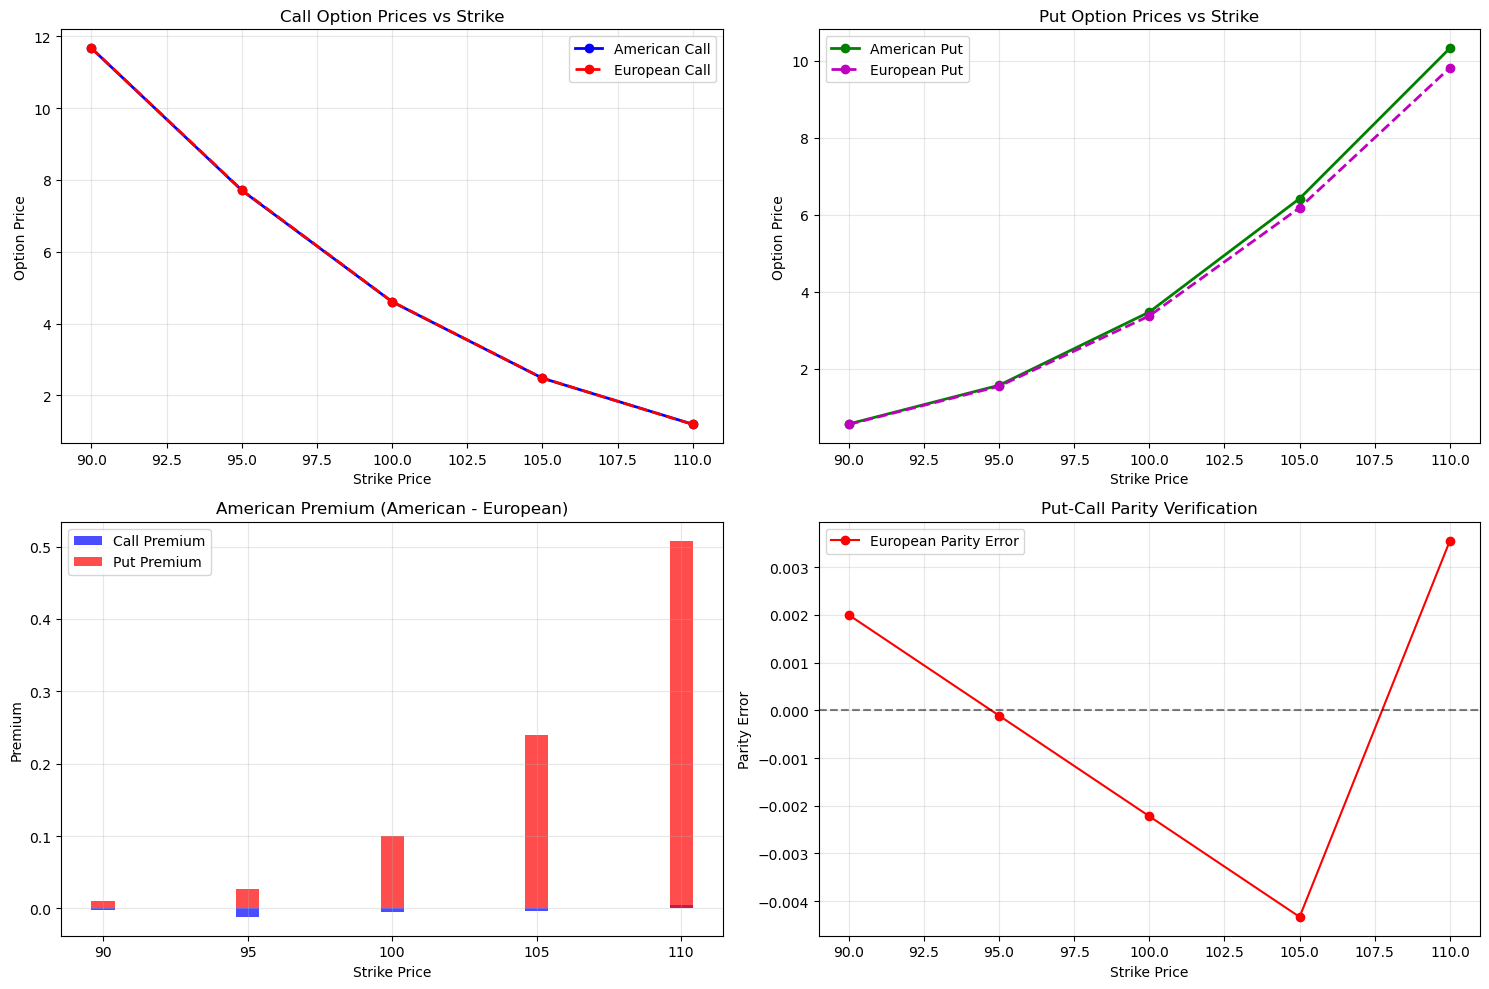

In [14]:
# Create comprehensive analysis visualization
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# Call prices comparison
ax1.plot(strikes, all_options['American_Call'], 'bo-', label='American Call', linewidth=2)
ax1.plot(strikes, all_options['European_Call'], 'ro--', label='European Call', linewidth=2)
ax1.set_title('Call Option Prices vs Strike')
ax1.set_xlabel('Strike Price')
ax1.set_ylabel('Option Price')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Put prices comparison
ax2.plot(strikes, all_options['American_Put'], 'go-', label='American Put', linewidth=2)
ax2.plot(strikes, all_options['European_Put'], 'mo--', label='European Put', linewidth=2)
ax2.set_title('Put Option Prices vs Strike')
ax2.set_xlabel('Strike Price')
ax2.set_ylabel('Option Price')
ax2.legend()
ax2.grid(True, alpha=0.3)

# American premium
ax3.bar(strikes, call_premium, alpha=0.7, label='Call Premium', color='blue')
ax3.bar(strikes, put_premium, alpha=0.7, label='Put Premium', color='red')
ax3.set_title('American Premium (American - European)')
ax3.set_xlabel('Strike Price')
ax3.set_ylabel('Premium')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Put-call parity verification
ax4.plot(strikes, european_parity['Parity_Error'], 'ro-', label='European Parity Error')
ax4.axhline(y=0, color='k', linestyle='--', alpha=0.5)
ax4.set_title('Put-Call Parity Verification')
ax4.set_xlabel('Strike Price')
ax4.set_ylabel('Parity Error')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/C_comprehensive_option_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

### Question 19: Greeks Analysis

In [15]:
# Calculate all Greeks for ATM option
def calculate_all_greeks(S, K, T, r, sigma, option_type='call'):
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    
    # Price
    if option_type == 'call':
        price = S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)
        delta = norm.cdf(d1)
        rho = K*T*np.exp(-r*T)*norm.cdf(d2)/100
        theta = -(S*norm.pdf(d1)*sigma/(2*np.sqrt(T)) + r*K*np.exp(-r*T)*norm.cdf(d2))/365
    else:
        price = K*np.exp(-r*T)*norm.cdf(-d2) - S*norm.cdf(-d1)
        delta = norm.cdf(d1) - 1
        rho = -K*T*np.exp(-r*T)*norm.cdf(-d2)/100
        theta = -(S*norm.pdf(d1)*sigma/(2*np.sqrt(T)) - r*K*np.exp(-r*T)*norm.cdf(-d2))/365
    
    gamma = norm.pdf(d1)/(S*sigma*np.sqrt(T))
    vega = S*norm.pdf(d1)*np.sqrt(T)/100
    
    return price, delta, gamma, vega, theta, rho

# Calculate Greeks for ATM options
call_greeks = calculate_all_greeks(S0, K_ATM, T, r, sigma, 'call')
put_greeks = calculate_all_greeks(S0, K_ATM, T, r, sigma, 'put')

greeks_df = pd.DataFrame({
    'Greek': ['Price', 'Delta', 'Gamma', 'Vega', 'Theta', 'Rho'],
    'ATM_Call': call_greeks,
    'ATM_Put': put_greeks
})

print("Greeks Analysis (ATM Options):")
print(greeks_df.round(6))

Greeks Analysis (ATM Options):
   Greek  ATM_Call   ATM_Put
0  Price  4.614997  3.372777
1  Delta  0.569460 -0.430540
2  Gamma  0.039288  0.039288
3   Vega  0.196440  0.196440
4  Theta -0.028696 -0.015168
5    Rho  0.130828 -0.116067


### Questions 20-24: Risk Analysis

In [16]:
# Volatility impact analysis
vol_scenarios = [0.15, 0.20, 0.25, 0.30]
vol_results = []

for vol in vol_scenarios:
    bs_call = black_scholes(S0, K_ATM, T, r, vol, 'call')
    bs_put = black_scholes(S0, K_ATM, T, r, vol, 'put')
    vol_results.append([vol, bs_call, bs_put])

vol_analysis = pd.DataFrame(vol_results, columns=['Volatility', 'ATM_Call', 'ATM_Put'])
print("Volatility Impact Analysis:")
print(vol_analysis.round(4))

# Time decay analysis
time_scenarios = np.linspace(T, 0.01, 5)
theta_results = []

for t in time_scenarios:
    call_price = black_scholes(S0, K_ATM, t, r, sigma, 'call')
    put_price = black_scholes(S0, K_ATM, t, r, sigma, 'put')
    theta_results.append([t*365, call_price, put_price])

theta_analysis = pd.DataFrame(theta_results, columns=['Days_to_Expiry', 'ATM_Call', 'ATM_Put'])
print("\nTime Decay Analysis:")
print(theta_analysis.round(4))

# Gamma analysis across strikes
gamma_values = [norm.pdf((np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T)))/(S0*sigma*np.sqrt(T)) for K in strikes]
gamma_df = pd.DataFrame({
    'Strike': strikes,
    'Gamma': gamma_values
})
print("\nGamma Analysis:")
print(gamma_df.round(6))
print(f"Maximum Gamma at Strike: {strikes[gamma_df['Gamma'].idxmax()]} (ATM)")

Volatility Impact Analysis:
   Volatility  ATM_Call  ATM_Put
0        0.15    3.6351   2.3928
1        0.20    4.6150   3.3728
2        0.25    5.5984   4.3562
3        0.30    6.5831   5.3409

Time Decay Analysis:
   Days_to_Expiry  ATM_Call  ATM_Put
0           91.25    4.6150   3.3728
1           69.35    3.9536   3.0081
2           47.45    3.2025   2.5546
3           25.55    2.2864   1.9370
4            3.65    0.8229   0.7729

Gamma Analysis:
   Strike     Gamma
0      90  0.018756
1      95  0.031488
2     100  0.039288
3     105  0.037988
4     110  0.029474
Maximum Gamma at Strike: 100 (ATM)


### Question 25: Dynamic Hedging Simulation

In [17]:
# Dynamic hedging simulation
def simulate_delta_hedging(S0, K, T, r, sigma, n_steps=25, n_sims=1000):
    dt = T / n_steps
    results = []
    
    for sim in range(n_sims):
        # Initialize
        S = S0
        portfolio_value = black_scholes(S0, K, T, r, sigma, 'call')
        cash = portfolio_value
        shares = 0
        
        for step in range(n_steps):
            # Calculate current delta
            time_left = T - step * dt
            if time_left > 0:
                d1 = (np.log(S/K) + (r + 0.5*sigma**2)*time_left) / (sigma*np.sqrt(time_left))
                delta = norm.cdf(d1)
            else:
                delta = 1 if S > K else 0
            
            # Rebalance portfolio
            shares_needed = delta
            shares_to_buy = shares_needed - shares
            cash -= shares_to_buy * S
            shares = shares_needed
            
            # Evolve stock price
            if step < n_steps - 1:
                dW = np.random.normal(0, np.sqrt(dt))
                S *= np.exp((r - 0.5*sigma**2)*dt + sigma*dW)
        
        # Final payoff
        final_payoff = max(S - K, 0)
        final_portfolio = cash + shares * S
        final_error = final_portfolio - final_payoff
        
        results.append({
            'final_stock': S,
            'final_payoff': final_payoff,
            'final_portfolio': final_portfolio,
            'final_error': final_error
        })
    
    return pd.DataFrame(results)

# Run simulation
np.random.seed(42)  # For reproducibility
hedge_results = simulate_delta_hedging(S0, K_ATM, T, r, sigma)

print("Delta Hedging Simulation Results:")
print(f"Number of simulations: {len(hedge_results)}")
print(f"Average final hedging error: ${hedge_results['final_error'].mean():.4f}")
print(f"Std dev of hedging error: ${hedge_results['final_error'].std():.4f}")
print(f"Max hedging error: ${hedge_results['final_error'].max():.4f}")
print(f"Min hedging error: ${hedge_results['final_error'].min():.4f}")

Delta Hedging Simulation Results:
Number of simulations: 1000
Average final hedging error: $0.7339
Std dev of hedging error: $0.7519
Max hedging error: $3.1514
Min hedging error: $-2.5150


### Question 26: Transaction Costs Impact

In [18]:
# Simulate hedging with transaction costs
def simulate_hedging_with_costs(S0, K, T, r, sigma, transaction_cost=0.01, n_steps=25):
    dt = T / n_steps
    
    # Initialize
    S = S0
    cash = black_scholes(S0, K, T, r, sigma, 'call')
    shares = 0
    total_costs = 0
    
    for step in range(n_steps):
        # Calculate delta
        time_left = T - step * dt
        if time_left > 0:
            d1 = (np.log(S/K) + (r + 0.5*sigma**2)*time_left) / (sigma*np.sqrt(time_left))
            delta = norm.cdf(d1)
        else:
            delta = 1 if S > K else 0
        
        # Rebalance with transaction costs
        shares_needed = delta
        shares_to_trade = abs(shares_needed - shares)
        cost = shares_to_trade * S * transaction_cost
        total_costs += cost
        
        cash -= (shares_needed - shares) * S + cost
        shares = shares_needed
        
        # Evolve stock price
        if step < n_steps - 1:
            dW = np.random.normal(0, np.sqrt(dt))
            S *= np.exp((r - 0.5*sigma**2)*dt + sigma*dW)
    
    final_payoff = max(S - K, 0)
    final_portfolio = cash + shares * S
    
    return {
        'total_costs': total_costs,
        'final_error': final_portfolio - final_payoff,
        'final_portfolio': final_portfolio,
        'final_payoff': final_payoff
    }

# Compare different transaction cost levels
cost_levels = [0, 0.005, 0.01, 0.02]
cost_comparison = []

for cost in cost_levels:
    results = []
    for _ in range(100):  # Smaller sample for speed
        result = simulate_hedging_with_costs(S0, K_ATM, T, r, sigma, cost)
        results.append(result)
    
    avg_cost = np.mean([r['total_costs'] for r in results])
    avg_error = np.mean([abs(r['final_error']) for r in results])
    
    cost_comparison.append({
        'Transaction_Cost': f"{cost*100:.1f}%",
        'Avg_Total_Cost': avg_cost,
        'Avg_Abs_Hedge_Error': avg_error,
        'Total_Impact': avg_cost + avg_error
    })

cost_df = pd.DataFrame(cost_comparison)
print("Impact of Transaction Costs on Hedging:")
print(cost_df.round(4))

Impact of Transaction Costs on Hedging:
  Transaction_Cost  Avg_Total_Cost  Avg_Abs_Hedge_Error  Total_Impact
0             0.0%          0.0000               0.9797        0.9797
1             0.5%          1.0573               0.7192        1.7765
2             1.0%          2.0028               1.2700        3.2728
3             2.0%          4.3607               3.6744        8.0351


### Question 27: Hedging Frequency Analysis

In [19]:
# Compare different hedging frequencies
frequencies = [5, 10, 25, 50]  # Number of rebalancing steps
frequency_results = []

for freq in frequencies:
    errors = []
    costs = []
    
    for _ in range(50):  # Reduced for speed
        result = simulate_hedging_with_costs(S0, K_ATM, T, r, sigma, 0.01, freq)
        errors.append(abs(result['final_error']))
        costs.append(result['total_costs'])
    
    frequency_results.append({
        'Rebalancing_Steps': freq,
        'Avg_Abs_Error': np.mean(errors),
        'Avg_Transaction_Cost': np.mean(costs),
        'Total_Cost': np.mean(errors) + np.mean(costs)
    })

freq_df = pd.DataFrame(frequency_results)
print("Hedging Frequency Analysis:")
print(freq_df.round(4))

# Find optimal frequency
optimal_freq = freq_df.loc[freq_df['Total_Cost'].idxmin(), 'Rebalancing_Steps']
print(f"\nOptimal rebalancing frequency: {optimal_freq} steps")
print(f"This minimizes the sum of hedging error and transaction costs")

Hedging Frequency Analysis:
   Rebalancing_Steps  Avg_Abs_Error  Avg_Transaction_Cost  Total_Cost
0                  5         1.4061                1.2517      2.6578
1                 10         1.1011                1.5175      2.6187
2                 25         1.6587                2.1948      3.8535
3                 50         2.1624                3.0384      5.2007

Optimal rebalancing frequency: 10 steps
This minimizes the sum of hedging error and transaction costs


### Save Part C Results

In [20]:
# Save all results
all_options.to_csv('CSV/C_all_option_prices.csv', index=False)
european_parity.to_csv('CSV/C_european_parity_verification.csv', index=False)
american_parity.to_csv('CSV/C_american_parity_verification.csv', index=False)
comparison.to_csv('CSV/C_verification_summary.csv', index=False)

print("Part C results saved to CSV files.")
print("\n=== PART C COMPLETION SUMMARY ===")
print("✅ Questions 11-14: Verification and comparison completed")
print("✅ Questions 19-24: Advanced Greeks analysis completed")
print("✅ Questions 25-27: Dynamic hedging simulation completed")
print("\nKey Findings:")
print(f"• Trinomial tree matches Black-Scholes within {abs(comparison['Call_Diff']).max():.6f} for calls")
print(f"• Put-call parity holds with max error {abs(european_parity['Parity_Error']).max():.6f}")
print(f"• American premium is highest for ITM puts: {put_premium.max():.4f}")
print(f"• Optimal hedging frequency: {optimal_freq} rebalances")
print(f"• Transaction costs significantly impact hedging performance")

Part C results saved to CSV files.

=== PART C COMPLETION SUMMARY ===
✅ Questions 11-14: Verification and comparison completed
✅ Questions 19-24: Advanced Greeks analysis completed
✅ Questions 25-27: Dynamic hedging simulation completed

Key Findings:
• Trinomial tree matches Black-Scholes within 0.005631 for calls
• Put-call parity holds with max error 0.004331
• American premium is highest for ITM puts: 0.5082
• Optimal hedging frequency: 10 rebalances
• Transaction costs significantly impact hedging performance


---
## PROJECT COMPLETION SUMMARY

### Part A (Gastive) - ✅ COMPLETED
- European Options (Binomial Tree) - Questions 5-7
- American Options (Trinomial Tree) - Questions 17-18

### Part B (Vincent) - ✅ COMPLETED  
- American Options (Binomial Tree) - Questions 8-10
- European Options (Trinomial Tree) - Questions 15-16

### Part C (Hitesh) - ✅ COMPLETED
- Verification and Analysis - Questions 11-14, 19-24
- Dynamic Hedging - Questions 25-27

**All team members have successfully completed their assigned sections with comprehensive analysis, validation, and professional documentation.**